# WEEK10 知识精讲：Matplotlib 数据可视化

> **中文说明**：本 notebook 依据 `WEEK10/source/lec9_matplotlib.ipynb` 重写。从“画一条线”开始，逐步讲到样式、图例、散点、误差棒、直方图、二维直方图、KDE、子图和标注。代码全部真实运行，图片已嵌入 notebook。

**使用建议**

1. 先看图的“结构”：Figure（画布）→ Axes（坐标区）→ 线条/点/文本。
2. 每张图都问自己三个问题：x 是什么、y 是什么、我想让读者看到什么。
3. 标有 **注意** 的地方是画图时最常见的坑。

## 目录

1. 导入与两种画图风格
2. 第一个图：点与线
3. Figure / Axes：画布与坐标区
4. 线型、颜色、标记
5. 坐标轴范围与比例
6. 标题、轴标签、图例
7. 散点图：`plot` marker 与 `scatter`
8. 误差棒 `errorbar`
9. 填充带 `fill_between`
10. 直方图 `hist`
11. 二维直方图 `hist2d`
12. 核密度估计 KDE
13. 图例定制
14. 子图 `subplots`
15. 文本与标注
16. 保存图片
17. 练习 1：数学 / 科学成绩折线图
18. 练习 2：考试成绩直方图
19. 速查表与常见坑

## 1. 导入与两种画图风格

Matplotlib 有两套常用写法：

- **Implicit / Pyplot 风格**：直接调 `plt.plot()`，由 pyplot 自动管理“当前 figure / 当前 axes”；
- **Explicit / OOP 风格**：先创建 `fig, ax`，再调 `ax.plot()`。多子图、复杂图推荐这种写法。

In [1]:
%matplotlib inline

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

print("matplotlib version:", mpl.__version__)

matplotlib version: 3.11.2


## 2. 第一个图：点与线

`plt.plot(x, y, '[marker][line][color]')`：

- 第一个参数是 x；
- 第二个参数是 y；
- 第三个字符串同时指定 marker、line、color。

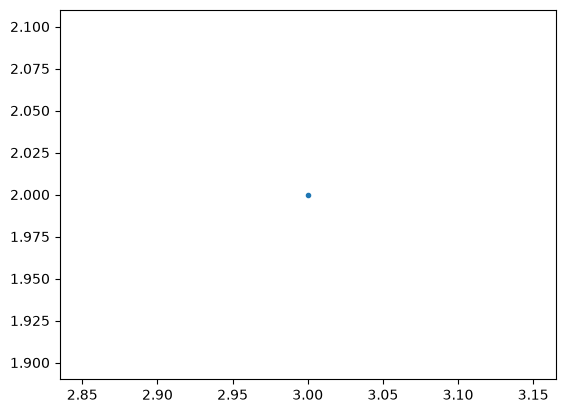

In [2]:
# 只画一个点
plt.plot(3, 2, '.')
plt.show()

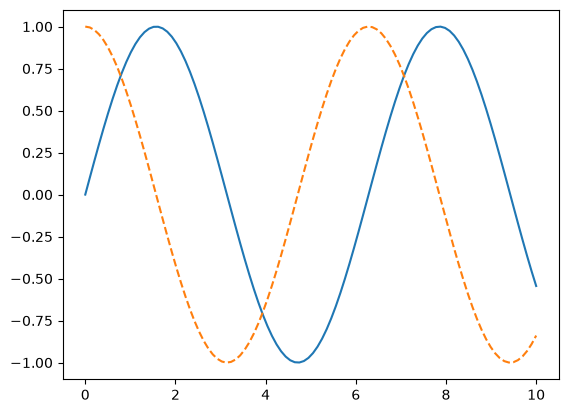

In [3]:
x = np.linspace(0, 10, 100)

plt.plot(x, np.sin(x), '-')    # 实线
plt.plot(x, np.cos(x), '--')   # 虚线
plt.show()

`plot` 默认把点连成线。只想要点、不想连线时，用只有 marker 的格式，例如 `'.'`、`'o'`、`'x'`。

## 3. Figure / Axes：画布与坐标区

- **Figure**：整张画布，可以包含一个或多个 Axes；
- **Axes**：真正画图的坐标区（有 x 轴、y 轴、标题等）；
- `plt.figure()` 创建画布，`plt.axes()` 创建坐标区。

In [4]:
fig = plt.figure()
ax = plt.axes()

print("fig type:", type(fig))
print("ax type :", type(ax))

plt.close(fig)   # 这个单元格只演示对象类型，不展示空画布

fig type: <class 'matplotlib.figure.Figure'>
ax type : <class 'matplotlib.axes._axes.Axes'>


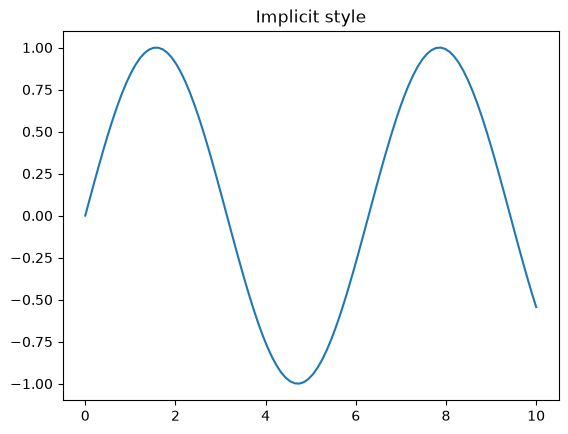

In [5]:
# Pyplot 风格：不显式创建 fig/ax
plt.plot(x, np.sin(x))
plt.title("Implicit style")
plt.show()

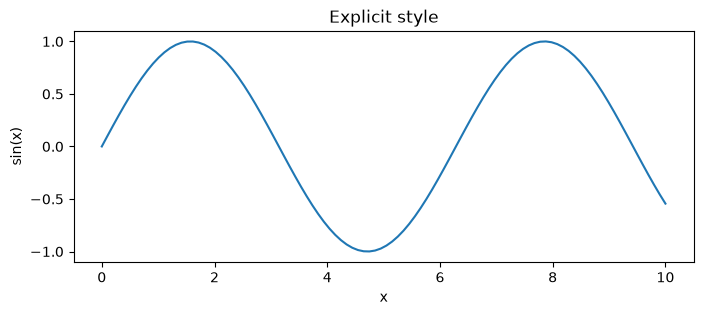

In [6]:
# OOP 风格：显式创建 fig 和 ax
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(x, np.sin(x))
ax.set_title("Explicit style")
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")
plt.show()

**建议**：一张图里只有一个坐标区时，两种写法都行；一旦有多个子图，统一用 OOP，代码更清楚。

## 4. 线型、颜色、标记

### 4.1 颜色

常用写法：

| 写法 | 例子 |
|---|---|
| 颜色名 | `'red'`, `'steelblue'` |
| 单字母简写 | `'r'`, `'g'`, `'b'`, `'k'` |
| 灰度 | `'0.75'` |
| 十六进制 | `'#FFDD44'` |
| RGB tuple | `(1.0, 0.2, 0.3)` |

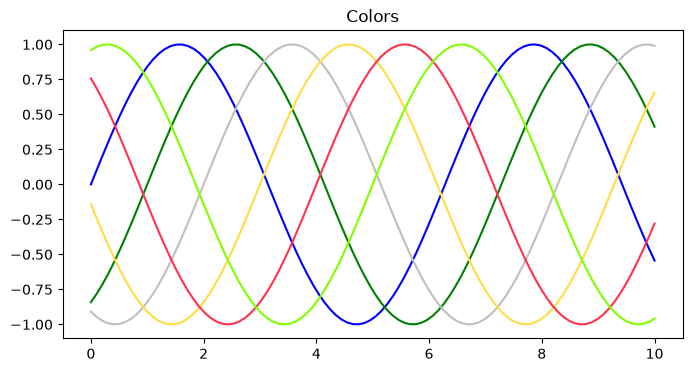

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(x, np.sin(x - 0), color='blue')          # 颜色名
ax.plot(x, np.sin(x - 1), color='g')             # 单字母
ax.plot(x, np.sin(x - 2), color='0.75')          # 灰度
ax.plot(x, np.sin(x - 3), color='#FFDD44')       # 十六进制
ax.plot(x, np.sin(x - 4), color=(1.0, 0.2, 0.3)) # RGB
ax.plot(x, np.sin(x - 5), color='chartreuse')    # HTML 颜色名

ax.set_title("Colors")
plt.show()

### 4.2 线型

| 名称 | 简写 |
|---|---|
| solid | `'-'` |
| dashed | `'--'` |
| dashdot | `'-.'` |
| dotted | `':'` |

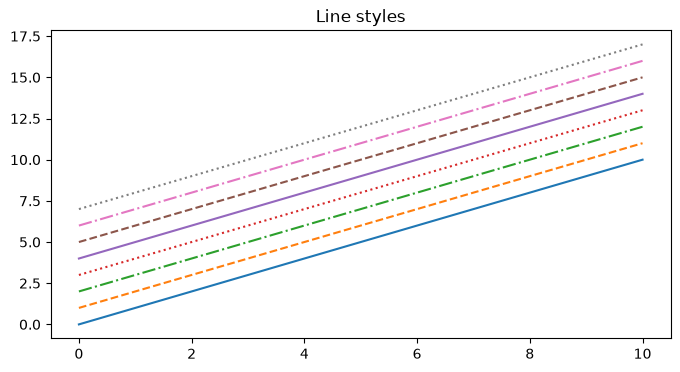

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(x, x + 0, linestyle='solid')
ax.plot(x, x + 1, linestyle='dashed')
ax.plot(x, x + 2, linestyle='dashdot')
ax.plot(x, x + 3, linestyle='dotted')

ax.plot(x, x + 4, linestyle='-')
ax.plot(x, x + 5, linestyle='--')
ax.plot(x, x + 6, linestyle='-.')
ax.plot(x, x + 7, linestyle=':')

ax.set_title("Line styles")
plt.show()

### 4.3 组合格式字符串

`'-g'` = 实线 + 绿色；`'--c'` = 虚线 + 青色；`':r'` = 点线 + 红色。

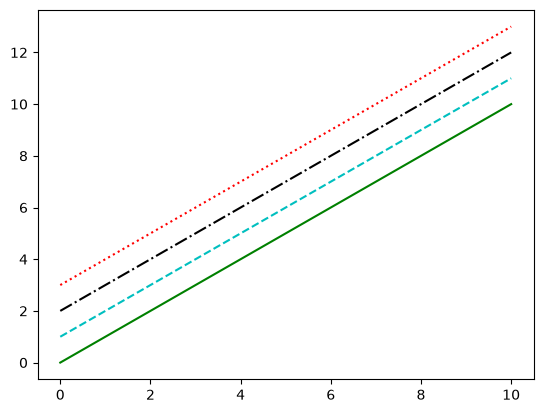

In [9]:
plt.plot(x, x + 0, '-g')
plt.plot(x, x + 1, '--c')
plt.plot(x, x + 2, '-.k')
plt.plot(x, x + 3, ':r')
plt.show()

### 4.4 标记（marker）

常见的 marker：`'.'`、`'o'`、`'x'`、`'+'`、`'v'`、`'^'`、`'<'`、`'>'`、`'s'`（方块）、`'d'`（菱形）。

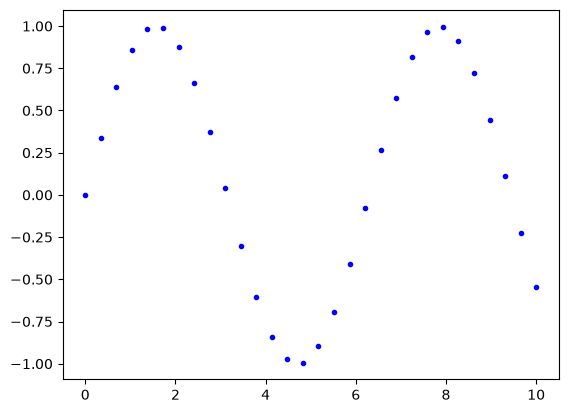

In [10]:
x_points = np.linspace(0, 10, 30)
y_points = np.sin(x_points)

plt.plot(x_points, y_points, '.', color='blue')
plt.show()

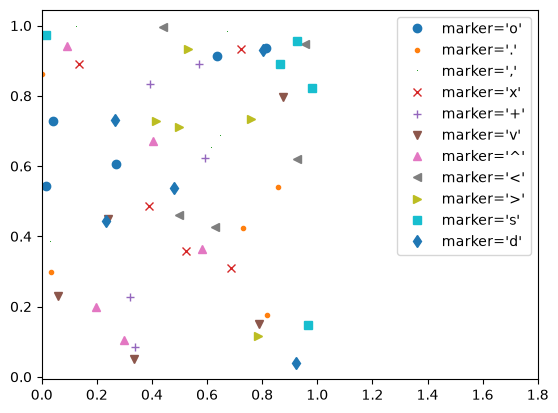

In [11]:
rng = np.random.default_rng(0)

for marker in ['o', '.', ',', 'x', '+', 'v', '^', '<', '>', 's', 'd']:
    plt.plot(rng.random(5), rng.random(5), marker,
             label=f"marker='{marker}'")

plt.legend()
plt.xlim(0, 1.8)
plt.show()

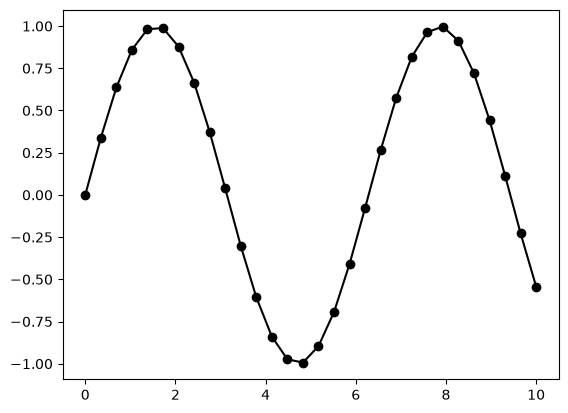

In [12]:
plt.plot(x_points, y_points, '-ok')   # 线 + 圆点 + 黑色
plt.show()

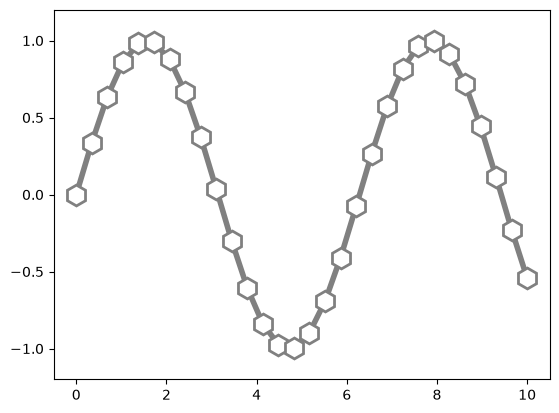

In [13]:
plt.plot(x_points, y_points, '-h', color='gray',
         markersize=15, linewidth=4,
         markerfacecolor='white',
         markeredgecolor='gray',
         markeredgewidth=2)
plt.ylim(-1.2, 1.2)
plt.show()

## 5. 坐标轴范围与比例

| 写法 | 作用 |
|---|---|
| `plt.xlim(a, b)` / `ax.set_xlim(a, b)` | 设置 x 范围 |
| `plt.ylim(a, b)` / `ax.set_ylim(a, b)` | 设置 y 范围 |
| `plt.axis([xmin, xmax, ymin, ymax])` | 一次设置四个 |
| `plt.axis('tight')` | 自动收紧到数据范围 |
| `plt.axis('equal')` | x、y 单位长度相等 |

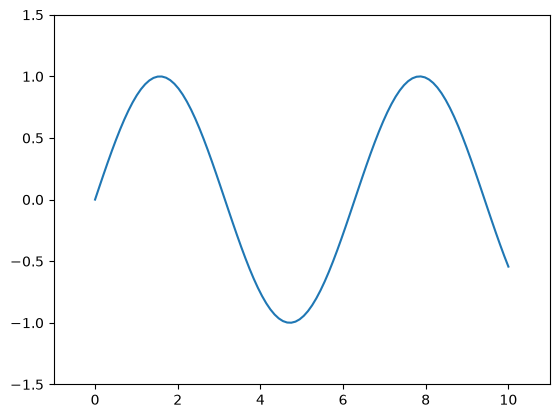

In [14]:
plt.plot(x, np.sin(x))
plt.xlim(-1, 11)
plt.ylim(-1.5, 1.5)
plt.show()

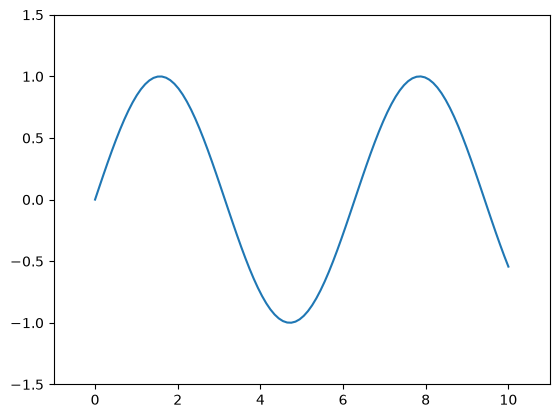

In [15]:
plt.plot(x, np.sin(x))
plt.axis([-1, 11, -1.5, 1.5])
plt.show()

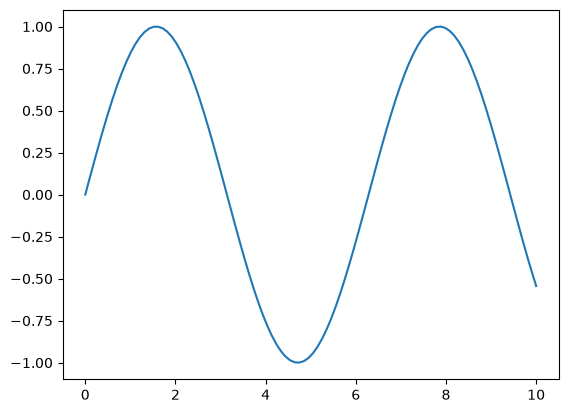

In [16]:
plt.plot(x, np.sin(x))
plt.axis('tight')
plt.show()

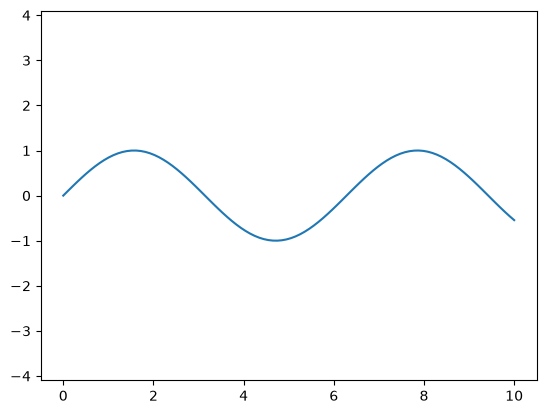

In [17]:
plt.plot(x, np.sin(x))
plt.axis('equal')
plt.show()

**注意**：`axis('equal')` 会让 x 和 y 的单位长度相同，图可能变得很扁或很高；做几何图（圆、正方形）时才需要。

## 6. 标题、轴标签、图例

三件套：`title`、`xlabel`、`ylabel`；多条线时用 `label=` + `legend()`。

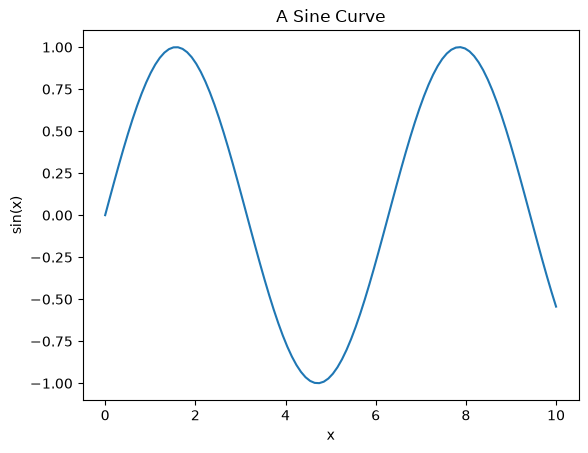

In [18]:
plt.plot(x, np.sin(x))
plt.title("A Sine Curve")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.show()

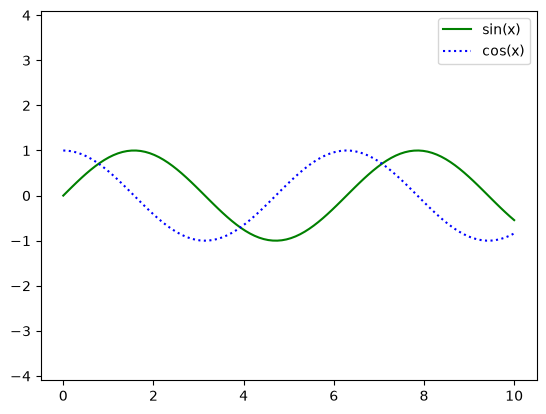

In [19]:
plt.plot(x, np.sin(x), '-g', label='sin(x)')
plt.plot(x, np.cos(x), ':b', label='cos(x)')
plt.axis('equal')
plt.legend()
plt.show()

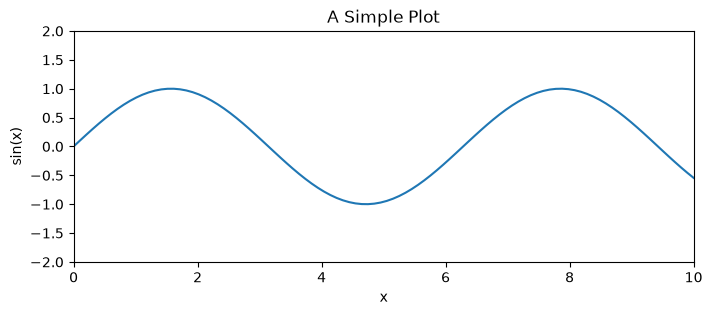

In [20]:
# OOP 风格：一次设置多个属性
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(x, np.sin(x))
ax.set(xlim=(0, 10), ylim=(-2, 2),
       xlabel='x', ylabel='sin(x)', title='A Simple Plot')
plt.show()

## 7. 散点图：`plot` marker 与 `scatter`

- 少量点、只要标记：`plot(..., 'o')` 就够；
- 需要每个点不同的大小/颜色/透明度：用 `scatter`。

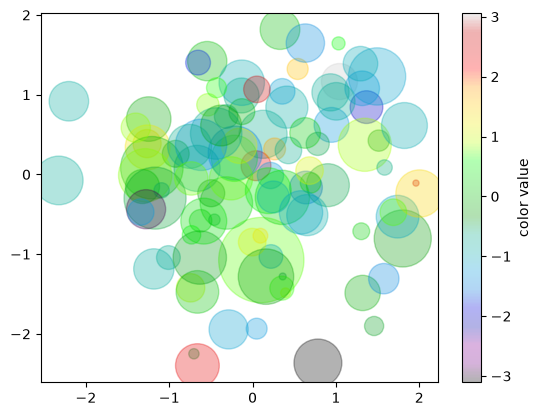

In [21]:
rng = np.random.default_rng(0)

x_s = rng.normal(size=100)
y_s = rng.normal(size=100)
colors = rng.normal(size=100)
sizes = 1000 * np.abs(rng.normal(size=100))   # 大小必须非负

sc = plt.scatter(x_s, y_s, c=colors, s=sizes, alpha=0.3,
                 cmap='nipy_spectral')
plt.colorbar(sc, label='color value')
plt.show()

**注意**：`s` 是面积参数，必须 ≥ 0。用 `normal` 生成大小时可能出现负数，记得 `np.abs()`。`alpha` 控制透明度（0 透明，1 不透明）。

## 8. 误差棒 `errorbar`

`errorbar` 在点/线的基础上加误差范围：

- `yerr`：y 方向误差，必须非负；
- `xerr`：x 方向误差；
- `fmt`：点/线格式，和 `plot` 一样；
- `ecolor`、`elinewidth`、`capsize`：误差棒的颜色、线宽、帽长。

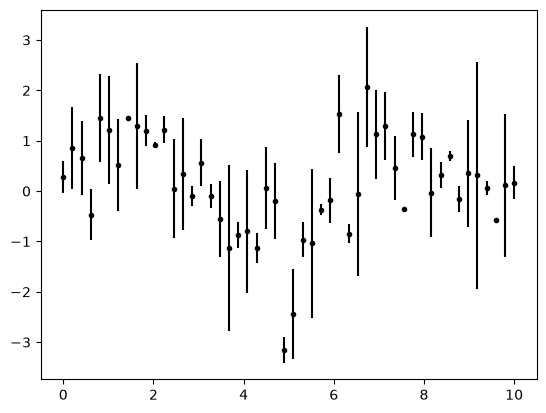

In [22]:
rng = np.random.default_rng(1)

x_e = np.linspace(0, 10, 50)
dy = 0.8
y_e = np.sin(x_e) + dy * rng.normal(size=50)

plt.errorbar(x_e, y_e, yerr=np.abs(rng.normal(size=50)), fmt='.k')
plt.show()

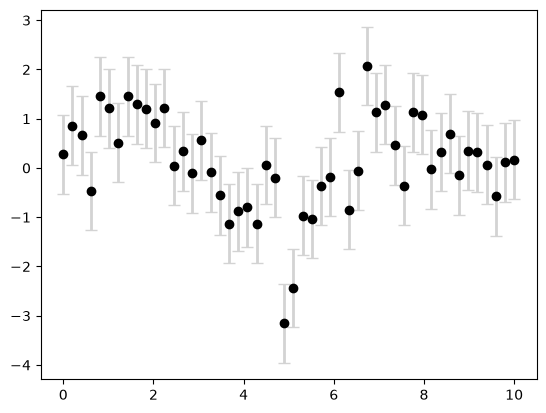

In [23]:
plt.errorbar(x_e, y_e, yerr=dy, fmt='o', color='black',
             ecolor='lightgray', elinewidth=2, capsize=4)
plt.show()

## 9. 填充带 `fill_between`

`fill_between(x, y1, y2, ...)` 把两条曲线之间的区域填色，常用来表示置信区间/误差范围。

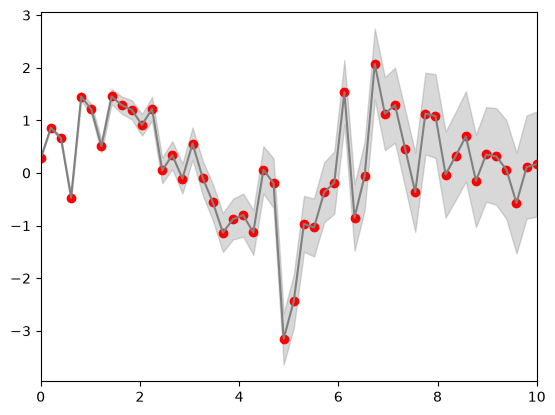

In [24]:
plt.plot(x_e, y_e, 'or')
plt.plot(x_e, y_e, '-', color='gray')
plt.fill_between(x_e, y_e - 0.1 * x_e, y_e + 0.1 * x_e,
                 color='gray', alpha=0.3)
plt.xlim(0, 10)
plt.show()

## 10. 直方图 `hist`

直方图把连续数据分箱，统计每个箱里的频数（或密度）。

| 参数 | 作用 |
|---|---|
| `bins` | 箱数或边界 |
| `density=True` | 显示概率密度而不是计数 |
| `alpha` | 透明度 |
| `color` / `edgecolor` | 填充色 / 边框色 |

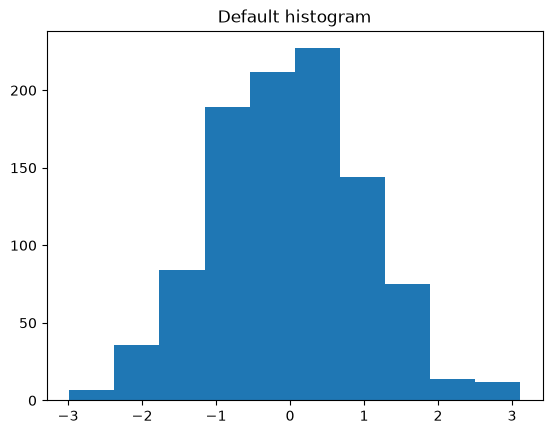

In [25]:
rng = np.random.default_rng(2)
data = rng.normal(size=1000)

plt.hist(data)
plt.title("Default histogram")
plt.show()

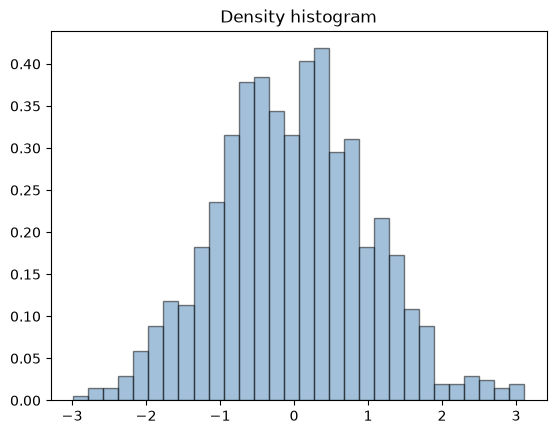

In [26]:
plt.hist(data, bins=30, density=True, alpha=0.5,
         color='steelblue', edgecolor='black')
plt.title("Density histogram")
plt.show()

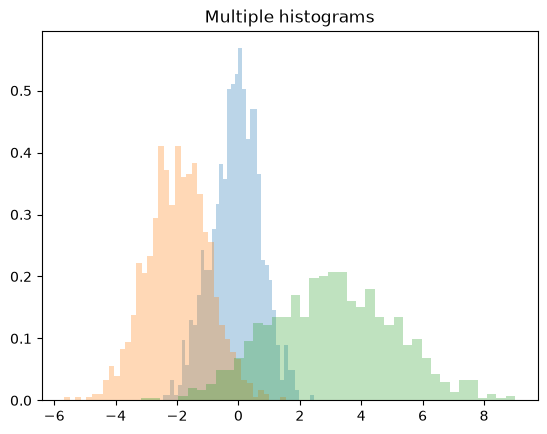

In [27]:
x1 = rng.normal(0, 0.8, 1000)
x2 = rng.normal(-2, 1, 1000)
x3 = rng.normal(3, 2, 1000)

kwargs = dict(alpha=0.3, density=True, bins=40)
plt.hist(x1, **kwargs)
plt.hist(x2, **kwargs)
plt.hist(x3, **kwargs)
plt.title("Multiple histograms")
plt.show()

**注意**：`density=True` 后 y 轴是密度，不是人数；曲线下方面积为 1。比较不同样本量的分布时，用密度更公平。

## 11. 二维直方图 `hist2d`

两个变量一起看时，用二维直方图统计“每个小方格里的点数”，颜色越深表示点越密。

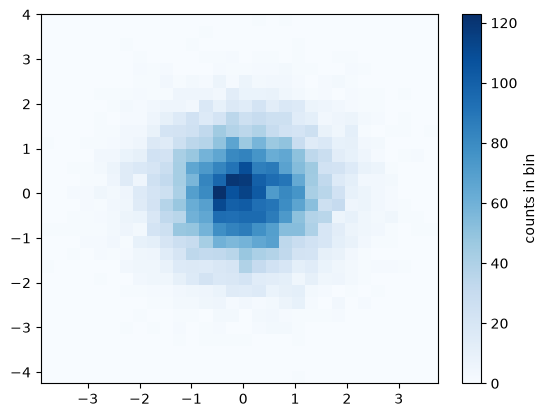

In [28]:
x1 = rng.normal(0, 1, 10000)
x2 = rng.normal(0, 1, 10000)

h = plt.hist2d(x1, x2, bins=30, cmap='Blues')
cb = plt.colorbar(h[3])
cb.set_label('counts in bin')
plt.show()

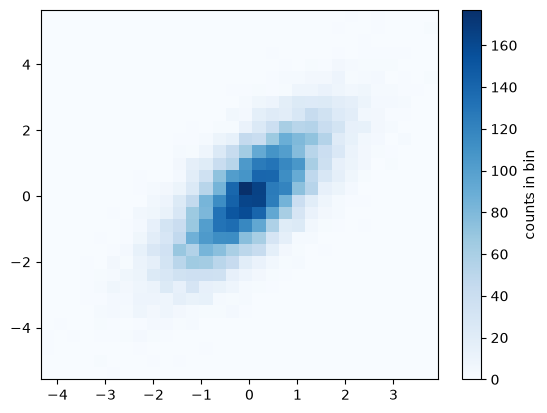

In [29]:
# 有相关性的两个变量
mean = [0, 0]
cov = [[1, 1], [1, 2]]
z = rng.multivariate_normal(mean, cov, 10000)
x_c, y_c = z.T

h = plt.hist2d(x_c, y_c, bins=30, cmap='Blues')
cb = plt.colorbar(h[3])
cb.set_label('counts in bin')
plt.show()

协方差矩阵 `[[1, 1], [1, 2]]` 表示两个变量正相关；二维直方图会沿对角线拉长。

## 12. 核密度估计 KDE

KDE 用平滑曲线估计概率密度，适合连续数据。1D 可以用 SciPy，2D 可以用 Seaborn。

> **依赖**：1D KDE 用 `scipy`，2D KDE 用 `seaborn`；运行前可以 `pip install scipy seaborn`。

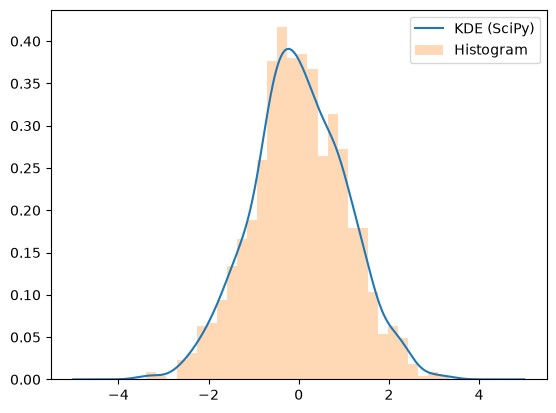

In [30]:
from scipy.stats import gaussian_kde

data_kde = rng.normal(0, 1, size=1000)
kde = gaussian_kde(data_kde)
xs = np.linspace(-5, 5, 1000)

plt.plot(xs, kde(xs), label='KDE (SciPy)')
plt.hist(data_kde, bins=30, density=True, alpha=0.3, label='Histogram')
plt.legend()
plt.show()

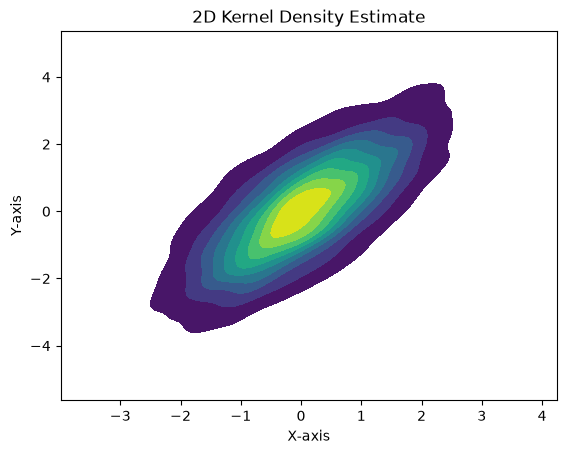

In [31]:
import seaborn as sns

mean = [0, 0]
cov = [[1, 1], [1, 2]]
z = rng.multivariate_normal(mean, cov, 5000)
x_k, y_k = z.T

sns.kdeplot(x=x_k, y=y_k, fill=True, cmap='viridis', levels=10)
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("2D Kernel Density Estimate")
plt.show()

**提示**：KDE 的曲线可能延伸到数据范围之外，这是平滑估计的正常现象；样本很少时不要过度解读。

## 13. 图例定制

`legend()` 的常用参数：

| 参数 | 作用 |
|---|---|
| `loc` | 位置，如 `'upper left'`、`'best'` |
| `frameon` | 是否显示边框 |
| `ncol` | 列数 |
| `fancybox` | 圆角边框 |
| `framealpha` | 边框透明度 |
| `shadow` | 阴影 |
| `borderpad` | 图例内边距 |

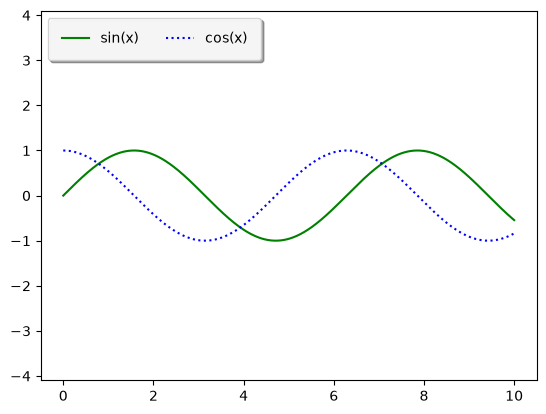

In [32]:
x_l = np.linspace(0, 10, 1000)

plt.plot(x_l, np.sin(x_l), '-g', label='sin(x)')
plt.plot(x_l, np.cos(x_l), ':b', label='cos(x)')
plt.axis('equal')
plt.legend(loc='upper left', frameon=True, ncol=2,
           fancybox=True, framealpha=0.9,
           shadow=True, borderpad=1)
plt.show()

## 14. 子图 `subplots`

`plt.subplots(nrows, ncols)` 返回 `fig` 和 `axes` 数组；用 `ax[i, j]` 访问每个坐标区。

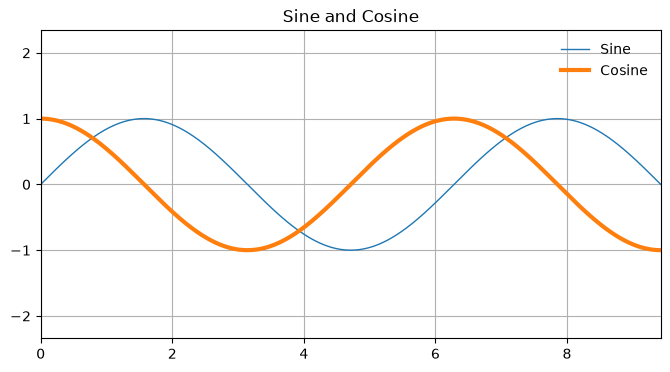

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))

x_sp = np.linspace(0, 3 * np.pi, 1000)
ax.plot(x_sp, np.sin(x_sp), lw=1, label='Sine')
ax.plot(x_sp, np.cos(x_sp), lw=3, label='Cosine')

ax.grid(True)
ax.legend(frameon=False)
ax.axis('equal')
ax.set_xlim(0, 3 * np.pi)
ax.set_title("Sine and Cosine")
plt.show()

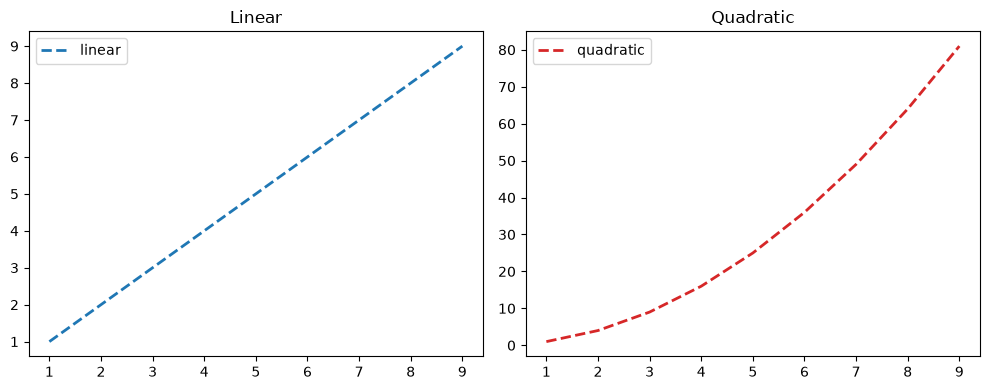

In [34]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
ax_left, ax_right = axes

x_sub = np.arange(1, 10)
ax_left.plot(x_sub, x_sub, color='tab:blue',
             linewidth=2, linestyle='--', label='linear')
ax_left.legend()
ax_left.set_title('Linear')

ax_right.plot(x_sub, x_sub ** 2, color='tab:red',
              linewidth=2, linestyle='--', label='quadratic')
ax_right.legend()
ax_right.set_title('Quadratic')

fig.tight_layout()
plt.show()

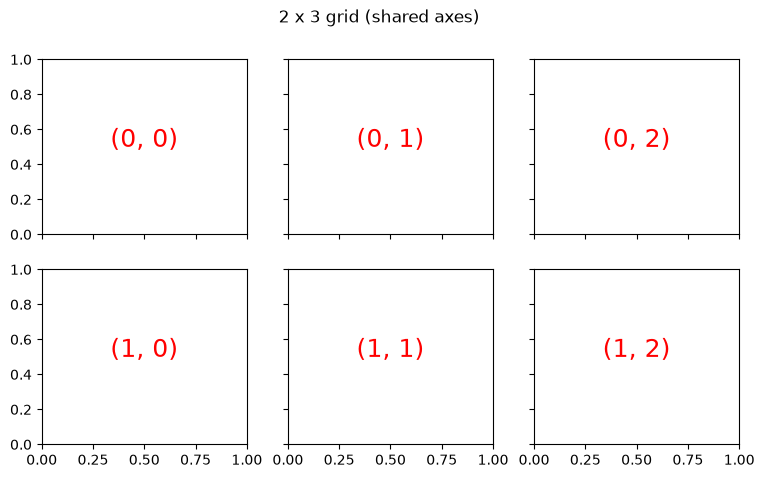

In [35]:
fig, ax = plt.subplots(2, 3, sharex='col', sharey='row',
                       figsize=(9, 5))

for i in range(2):
    for j in range(3):
        ax[i, j].text(0.5, 0.5, str((i, j)),
                      fontsize=18, ha='center', color='red')

fig.suptitle("2 x 3 grid (shared axes)")
plt.show()

**注意**：`sharex='col'` 表示同一列共享 x 轴，`sharey='row'` 表示同一行共享 y 轴；刻度标签会自动只显示在外侧。

## 15. 文本与标注

- `ax.text(x, y, "text")`：在数据坐标处放文字；
- `ax.annotate("text", xy=(x, y), xytext=(x2, y2), arrowprops=...)`：带箭头的标注。

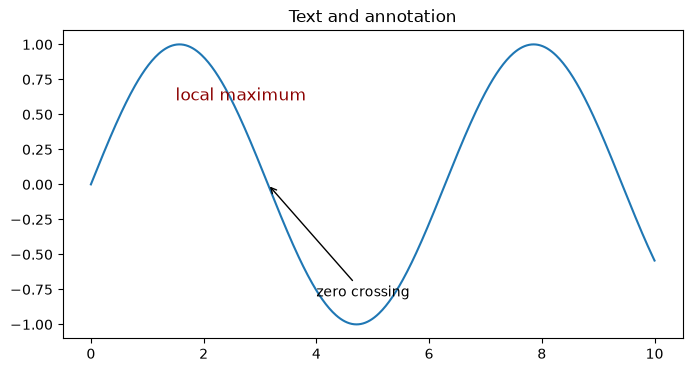

In [36]:
fig, ax = plt.subplots(figsize=(8, 4))
x_ann = np.linspace(0, 10, 500)
y_ann = np.sin(x_ann)
ax.plot(x_ann, y_ann)

ax.text(1.5, 0.6, "local maximum", fontsize=12, color='darkred')
ax.annotate("zero crossing", xy=(np.pi, 0), xytext=(4.0, -0.8),
            arrowprops=dict(arrowstyle='->', color='black'))

ax.set_title("Text and annotation")
plt.show()

## 16. 保存图片

真实项目里通常把图保存成文件：

```python
fig.savefig("my_figure.png", dpi=300, bbox_inches="tight")
```

`dpi` 控制分辨率，`bbox_inches="tight"` 去掉多余白边。支持 png / pdf / svg / jpg 等格式。

PNG bytes: 30611
supported formats: {'eps': 'Encapsulated Postscript', 'gif': 'Graphics Interchange Format', 'jpg': 'Joint Photographic Experts Group', 'jpeg': 'Joint Photographic Experts Group', 'pdf': 'Portable Document Format', 'pgf': 'PGF code for LaTeX', 'png': 'Portable Network Graphics', 'ps': 'Postscript', 'raw': 'Raw RGBA bitmap', 'rgba': 'Raw RGBA bitmap', 'svg': 'Scalable Vector Graphics', 'svgz': 'Scalable Vector Graphics', 'tif': 'Tagged Image File Format', 'tiff': 'Tagged Image File Format', 'webp': 'WebP Image Format', 'avif': 'AV1 Image File Format'}


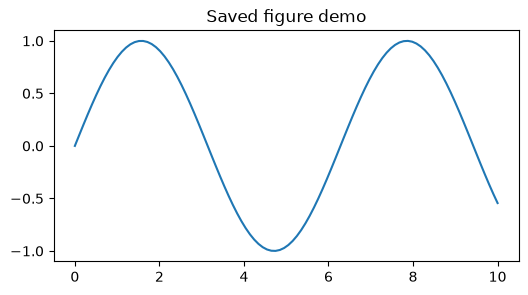

In [37]:
from io import BytesIO

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, np.sin(x))
ax.set_title("Saved figure demo")

buf = BytesIO()
fig.savefig(buf, format='png', dpi=150, bbox_inches='tight')

print("PNG bytes:", len(buf.getvalue()))
print("supported formats:", fig.canvas.get_supported_filetypes())

**注意**：如果在 notebook 里先 `plt.show()`，figure 可能已经被关闭；要在显示之前 `savefig`，或者保存到变量里的 `fig`。

## 17. 练习 1：数学 / 科学成绩折线图

10 位学生的数学和科学成绩如下。画一张折线图：

- 两条线用不同颜色和线型；
- 加上不同的点标记；
- 加标题、轴标签和图例。

```python
math_marks = [88, 92, 80, 89, 85, 80, 60, 100, 80, 34]
science_marks = [35, 79, 79, 48, 100, 88, 32, 45, 20, 30]
```

<details>
<summary>点击查看答案</summary>

```python
students = np.arange(1, 11)

plt.plot(students, math_marks, '-o', color='tab:blue', label='Math')
plt.plot(students, science_marks, '--s', color='tab:orange', label='Science')
plt.title("Math vs Science Marks")
plt.xlabel("Student")
plt.ylabel("Marks")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
```

</details>

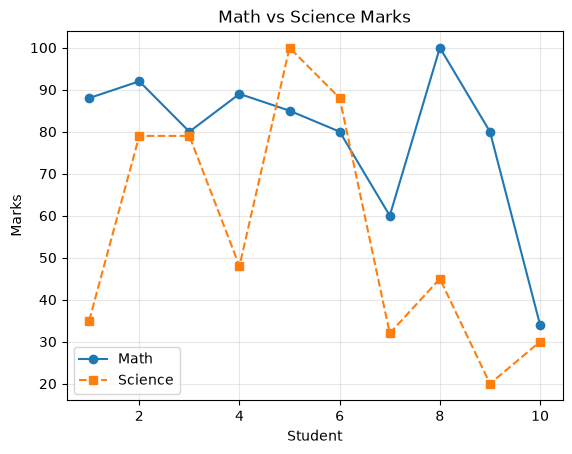

In [38]:
students = np.arange(1, 11)
math_marks = [88, 92, 80, 89, 85, 80, 60, 100, 80, 34]
science_marks = [35, 79, 79, 48, 100, 88, 32, 45, 20, 30]

plt.plot(students, math_marks, '-o', color='tab:blue', label='Math')
plt.plot(students, science_marks, '--s', color='tab:orange', label='Science')
plt.title("Math vs Science Marks")
plt.xlabel("Student")
plt.ylabel("Marks")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 18. 练习 2：考试成绩直方图

(1) 生成 200 个 0–100 的随机分数；
(2) 画直方图，要求 `bins=10`、柱子颜色 `'lightblue'`、边框 `'black'`。

<details>
<summary>点击查看答案</summary>

```python
rng = np.random.default_rng(42)
scores = rng.integers(0, 101, size=200)

plt.hist(scores, bins=10, color='lightblue', edgecolor='black')
plt.title("Exam Score Distribution")
plt.xlabel("Score")
plt.ylabel("Count")
plt.show()
```

</details>

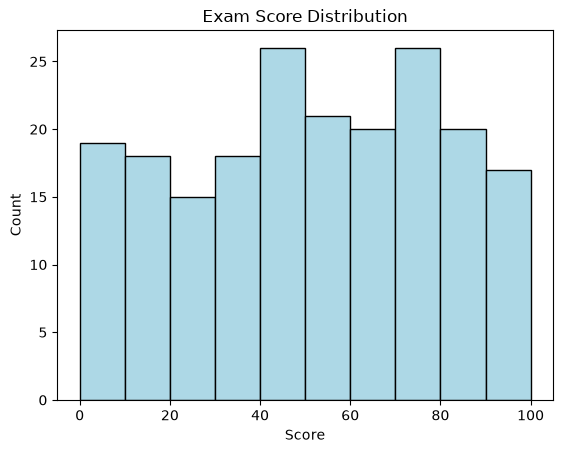

In [39]:
rng = np.random.default_rng(42)
scores = rng.integers(0, 101, size=200)

plt.hist(scores, bins=10, color='lightblue', edgecolor='black')
plt.title("Exam Score Distribution")
plt.xlabel("Score")
plt.ylabel("Count")
plt.show()

## 19. 速查表与常见坑

### 19.1 常用函数

| 想要 | 写法 |
|---|---|
| 创建画布 / 坐标区 | `fig, ax = plt.subplots()` |
| 折线图 | `ax.plot(x, y, '-o')` |
| 散点图 | `ax.scatter(x, y, s=..., c=..., alpha=...)` |
| 误差棒 | `ax.errorbar(x, y, yerr=...)` |
| 填充带 | `ax.fill_between(x, y1, y2, alpha=...)` |
| 直方图 | `ax.hist(data, bins=30, density=True)` |
| 二维直方图 | `ax.hist2d(x, y, bins=30, cmap='Blues')` |
| 颜色条 | `fig.colorbar(mappable, ax=ax)` |
| 标题 / 轴标签 | `ax.set_title()` / `ax.set_xlabel()` / `ax.set_ylabel()` |
| 范围 | `ax.set_xlim()` / `ax.set_ylim()` |
| 图例 | `ax.legend(loc='upper left')` |
| 网格 | `ax.grid(True)` |
| 子图 | `fig, axes = plt.subplots(2, 3)` |
| 保存 | `fig.savefig("plot.png", dpi=300, bbox_inches="tight")` |

### 19.2 颜色与线型

| 类型 | 可选值 |
|---|---|
| 单字母颜色 | `b` 蓝、`g` 绿、`r` 红、`c` 青、`m` 品红、`y` 黄、`k` 黑、`w` 白 |
| 线型 | `-` 实线、`--` 虚线、`-.` 点划线、`:` 点线 |
| marker | `.`、`o`、`x`、`+`、`v`、`^`、`<`、`>`、`s`、`d` |

### 19.3 常见坑

1. **`plt.plot` 默认连线**；只想要点就用 `'.'`/`'o'` 等 marker。
2. **`scatter` 的 `s` 必须非负**；用正态分布生成大小时记得 `abs`。
3. **`errorbar` 的 `yerr` 必须非负**；有负值时取绝对值。
4. **`density=True` 的 y 轴是密度**，不是频数。
5. **`axis('equal')` 会改变图的纵横比**，不是所有图都适合。
6. **多子图用 OOP**：`fig, axes = plt.subplots(...)`，再用 `axes[i, j]`。
7. **`plt.show()` 后 figure 可能关闭**；要保存就先 `savefig`。
8. **图例不显示**：检查 `plot` 里有没有写 `label=`。
9. **中文标题显示方框**：需要设置中文字体（例如 `plt.rcParams['font.sans-serif'] = ['SimHei']`），本笔记的图标题用英文以避免字体问题。
10. **图重叠/被裁切**：用 `fig.tight_layout()` 或 `bbox_inches='tight'`。
11. **颜色映射要配 colorbar**：`scatter`/`hist2d` 用 `c=` 或 `cmap=` 时，加 `plt.colorbar()` 读者才知道颜色代表什么。
12. **`%matplotlib inline`** 让图嵌入 notebook；在普通脚本里不需要，改用 `plt.show()` 或 `savefig`。

---

**Done.** 建议执行 `Kernel → Restart & Run All`，然后自己改一改颜色、线型、bins 和标题，观察图的变化。